# Simulación de opciones exóticas


In [44]:
import numpy as np
import matplotlib.pyplot as plt


one = [100, 111, 105, 90, 95, 102, 100]
two = [100, 102, 105, 107, 109, 105, 107]
three = [100, 110, 121, 120, 108, 100, 99]

k = 110

print(np.mean(one) - 100)
print(np.mean(three) - 100)

0.4285714285714306
8.285714285714292


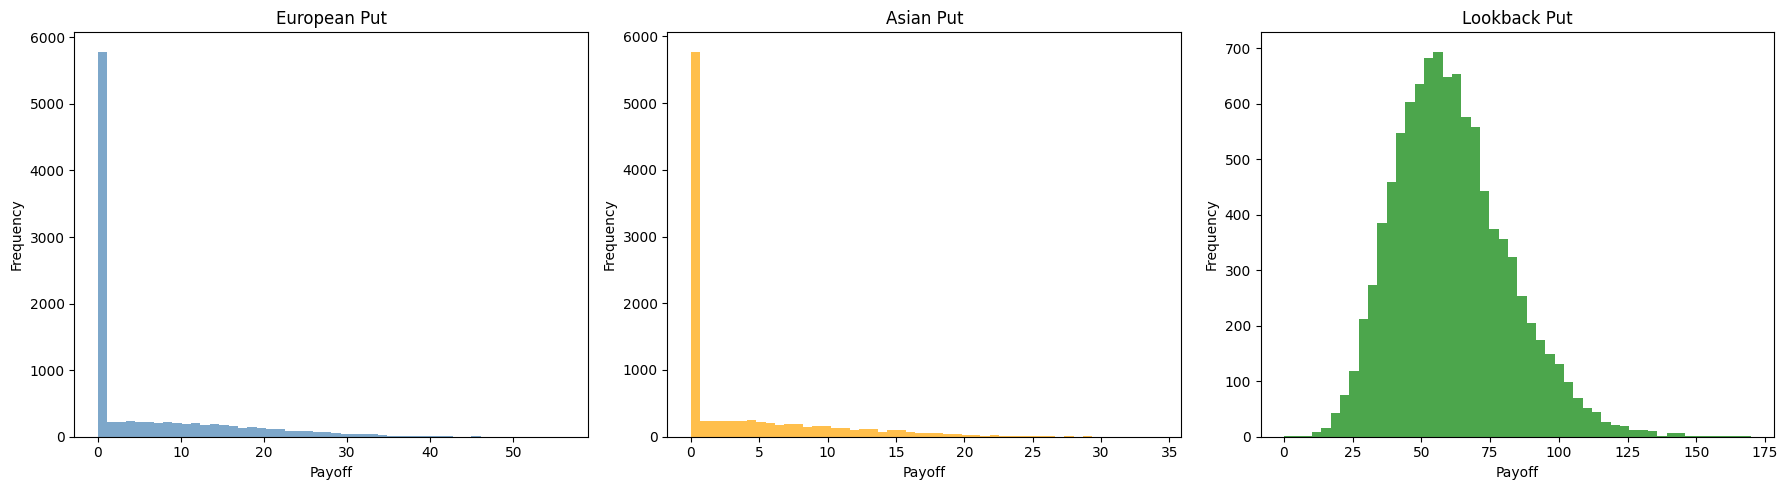

In [45]:
def create_paths(S0, r, sigma, T, steps, n_paths):
    dt = T / steps
    paths = np.zeros((steps + 1, n_paths))
    paths[0, :] = S0
    for t in range(1, steps + 1):
        paths[t, :] = paths[t - 1] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * np.random.normal(0, 1, n_paths))
    return paths


def payoff_europeo(paths, K , call = True):
    if call:
        return np.maximum(paths[-1] - K, 0)
    else:
        return np.maximum(K - paths[-1], 0)

def payoff_asian(paths, K , call = True):
    call = []
    put = []
    if call:
        for i in range(paths.shape[1]):
            call.append(np.mean(paths[:,i]))
        return np.maximum(np.array(call) - K, 0)
    else:
        for i in range(paths.shape[1]):
            put.append(np.mean(paths[:,i]))
        return np.maximum(K - np.array(put), 0)

def payoff_lookback(paths, K, call = True):
    if call:
        return np.maximum(np.max(paths) - paths[-1], 0)
    else:
        return np.maximum(paths[-1] - np.min(paths), 0)

paths = create_paths(100, 0.05, 0.2, 1, 252, 10000)
payoff_eu = payoff_europeo(paths, 100, call=False)
payoff_as = payoff_asian(paths, 100, call=False)
payoff_lo = payoff_lookback(paths, 100, call=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(payoff_eu, bins=50, alpha=0.7, color='steelblue')
axes[0].set_title('European Put')
axes[0].set_xlabel('Payoff')
axes[0].set_ylabel('Frequency')
axes[1].hist(payoff_as, bins=50, alpha=0.7, color='orange')
axes[1].set_title('Asian Put')
axes[1].set_xlabel('Payoff')
axes[1].set_ylabel('Frequency')
axes[2].hist(payoff_lo, bins=50, alpha=0.7, color='green')
axes[2].set_title('Lookback Put')
axes[2].set_xlabel('Payoff')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


In [46]:
import pandas as pd
paths = create_paths(100, 0.05, 0.2, 1, 252, 10000)
payoff_eu_put = payoff_europeo(paths, 100, call=False)
payoff_asian_put = payoff_asian(paths, 100, call=False)
payoff_lookback_put = payoff_lookback(paths, 100, call=False)
payoff_eu_call = payoff_europeo(paths, 100, call=True)
payoff_asian_call = payoff_asian(paths, 100, call=True)
payoff_lookback_call = payoff_lookback(paths, 100, call=True)

df = pd.DataFrame({
    'Call': [payoff_eu_call.mean(), payoff_asian_call.mean(), payoff_lookback_call.mean()],
    'Put': [payoff_eu_put.mean(), payoff_asian_put.mean(), payoff_lookback_put.mean()]
}, index=['European', 'Asian', 'Lookback'])

df

,Call,Put
European,10.804958,5.933531
Asian,3.505156,3.505156
Lookback,115.517904,55.777779


In [47]:
def up_and_in(B, payoff, paths, K, call=True):
    payoffs = []
    for i in range(paths.shape[1]):
        if np.max(paths[:, i]) >= B:
            p = payoff(paths[:, i], K, call)
            payoffs.append(p)
        else:
            payoffs.append(0)
    return np.array(payoffs)

def up_and_out(B, payoff, paths, K, call=True):
    payoffs = []
    for i in range(paths.shape[1]):
        if np.max(paths[:, i]) < B:
            p = payoff(paths[:, i], K, call)
            payoffs.append(p)
        else:
            payoffs.append(0)
    return np.array(payoffs)

def down_and_in(B, payoff, paths, K, call=True):
    payoffs = []
    for i in range(paths.shape[1]):
        if np.min(paths[:, i]) <= B:
            p = payoff(paths[:, i], K, call)
            payoffs.append(p)
        else:
            payoffs.append(0)
    return np.array(payoffs)

def down_and_out(B, payoff, paths, K, call=True):
    payoffs = []
    for i in range(paths.shape[1]):
        if np.min(paths[:, i]) > B:
            p = payoff(paths[:, i], K, call)
            payoffs.append(p)
        else:
            payoffs.append(0)
    return np.array(payoffs)
                
                

In [48]:
paths = create_paths(100, 0.05, 0.2, 0.5, 126, 10000)
p = up_and_in(110, payoff_europeo, paths, 100)